In [ ]:
import numpy as np
import pandas as pd
import random
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit

import matplotlib.pyplot as plt


In [ ]:
recipes = [
    {
        "recipe_id": "R1",
        "recipe_name": "Standard Black Tea",
        "tea_type": "black_tea",
        "sugar_g_per_l": 80,
        "starter_ml": 150,
        "water_volume_l": 1.0,
        "profile": "normal"
    },
    {
        "recipe_id": "R2",
        "recipe_name": "High Sugar Black Tea",
        "tea_type": "black_tea",
        "sugar_g_per_l": 100,
        "starter_ml": 150,
        "water_volume_l": 1.0,
        "profile": "sweet"
    },
    {
        "recipe_id": "R3",
        "recipe_name": "Low Sugar Black Tea",
        "tea_type": "black_tea",
        "sugar_g_per_l": 60,
        "starter_ml": 150,
        "water_volume_l": 1.0,
        "profile": "low_sugar"
    },
    {
        "recipe_id": "R4",
        "recipe_name": "Green Tea Standard",
        "tea_type": "green_tea",
        "sugar_g_per_l": 80,
        "starter_ml": 150,
        "water_volume_l": 1.0,
        "profile": "normal"
    },
    {
        "recipe_id": "R5",
        "recipe_name": "High Starter Ratio",
        "tea_type": "black_tea",
        "sugar_g_per_l": 80,
        "starter_ml": 220,
        "water_volume_l": 1.0,
        "profile": "fast"
    },
    {
        "recipe_id": "R6",
        "recipe_name": "Low Starter Ratio",
        "tea_type": "black_tea",
        "sugar_g_per_l": 80,
        "starter_ml": 90,
        "water_volume_l": 1.0,
        "profile": "slow"
    },
    {
        "recipe_id": "R7",
        "recipe_name": "Oolong Mixed Tea",
        "tea_type": "oolong_mixed",
        "sugar_g_per_l": 85,
        "starter_ml": 150,
        "water_volume_l": 1.0,
        "profile": "normal"
    }
]

BATCHES_PER_RECIPE = 50
DAYS_PER_BATCH = 14

print("Total recipe profiles:", len(recipes))
print("Batches per recipe:", BATCHES_PER_RECIPE)
print("Days per batch:", DAYS_PER_BATCH)
print("Expected rows:", len(recipes) * BATCHES_PER_RECIPE * DAYS_PER_BATCH)

Total recipe profiles: 7
Batches per recipe: 50
Days per batch: 14
Expected rows: 4900


In [ ]:
def classify_kombucha_status(
    temperature_c,
    humidity_percent,
    ph,
    brix,
    fermentation_day
):
    """
    Rule-Based Fermentation Assessment Model v1.1.

    Catatan penting:
    Model ini hanya dipakai sebagai decision-support label
    untuk dataset simulasi, bukan validasi keamanan pangan nyata.
    """

    if temperature_c > 30:
        return {
            "status": "temperature_warning",
            "recommendation": "Move the batch to a cooler area and monitor closely.",
            "rule_triggered": "R1_high_temperature_warning",
            "risk_flag": "warning"
        }

    if temperature_c < 18:
        return {
            "status": "manual_check",
            "recommendation": "Low temperature may slow fermentation. Continue monitoring.",
            "rule_triggered": "R2_low_temperature_slow_fermentation",
            "risk_flag": "caution"
        }

    if fermentation_day > 14 and (ph < 3.2 or brix < 5.0):
        return {
            "status": "too_sour",
            "recommendation": "Extended fermentation suggests possible over-fermentation.",
            "rule_triggered": "R11_extended_over_fermentation",
            "risk_flag": "caution"
        }

    if ph > 4.2:
        return {
            "status": "too_early",
            "recommendation": "Continue fermentation and check again within 24 hours.",
            "rule_triggered": "R3_early_acidity_stage",
            "risk_flag": "normal"
        }

    if ph < 3.0 or brix < 5.0:
        return {
            "status": "too_sour",
            "recommendation": "The batch may be too acidic or low in residual sweetness.",
            "rule_triggered": "R4_R5_over_acidic_or_low_sweetness",
            "risk_flag": "caution"
        }

    if fermentation_day < 5 and 3.2 <= ph <= 4.2:
        return {
            "status": "manual_check",
            "recommendation": "Acidity appears acceptable, but fermentation day is still early.",
            "rule_triggered": "R9_early_day_manual_check",
            "risk_flag": "caution"
        }

    if 3.2 <= ph <= 4.2 and brix > 8.0:
        return {
            "status": "still_sweet",
            "recommendation": "The batch is still sweet. Continue fermentation or start taste testing.",
            "rule_triggered": "R6_sweet_fermentation_stage",
            "risk_flag": "normal"
        }

    if 3.2 <= ph <= 4.2 and 5.0 <= brix <= 8.0:
        if fermentation_day >= 7:
            return {
                "status": "balanced",
                "recommendation": "Start taste testing and consider bottling.",
                "rule_triggered": "R10_balanced_ready_window",
                "risk_flag": "normal"
            }

        return {
            "status": "balanced",
            "recommendation": "Balanced chemistry, but fermentation day is early. Perform manual taste check.",
            "rule_triggered": "R7_balanced_but_early",
            "risk_flag": "normal"
        }

    return {
        "status": "manual_check",
        "recommendation": "Ambiguous condition. Perform manual inspection.",
        "rule_triggered": "R8_ambiguous_condition",
        "risk_flag": "caution"
    }


# Quick test. Biar nggak sok percaya kode sendiri, kebiasaan buruk spesies software.
test_result = classify_kombucha_status(
    temperature_c=25.5,
    humidity_percent=68,
    ph=3.5,
    brix=6.5,
    fermentation_day=7
)

print(test_result)

{'status': 'balanced', 'recommendation': 'Start taste testing and consider bottling.', 'rule_triggered': 'R10_balanced_ready_window', 'risk_flag': 'normal'}


In [ ]:
np.random.seed(42)
random.seed(42)
def get_rates_by_profile(profile):
    """
    Menentukan kecepatan simulasi fermentasi.
    pH akan turun seiring hari.
    Brix akan turun seiring hari.
    """

    if profile == "fast":
        ph_drop_rate = np.random.uniform(0.15, 0.21)
        brix_drop_rate = np.random.uniform(0.55, 0.80)

    elif profile == "slow":
        ph_drop_rate = np.random.uniform(0.06, 0.10)
        brix_drop_rate = np.random.uniform(0.22, 0.36)

    elif profile == "sweet":
        ph_drop_rate = np.random.uniform(0.10, 0.15)
        brix_drop_rate = np.random.uniform(0.35, 0.50)

    elif profile == "low_sugar":
        ph_drop_rate = np.random.uniform(0.11, 0.16)
        brix_drop_rate = np.random.uniform(0.45, 0.65)

    else:
        ph_drop_rate = np.random.uniform(0.10, 0.15)
        brix_drop_rate = np.random.uniform(0.38, 0.55)

    return ph_drop_rate, brix_drop_rate


rows = []

for recipe in recipes:
    for batch_num in range(1, BATCHES_PER_RECIPE + 1):

        batch_id = f"KB-{recipe['recipe_id']}-{batch_num:03d}"

        sugar_actual = np.random.normal(recipe["sugar_g_per_l"], 4)
        starter_actual = np.random.normal(recipe["starter_ml"], 12)

        base_temp = np.random.normal(25, 2)
        base_humidity = np.random.normal(68, 7)

        # Beberapa batch sengaja dibuat di lingkungan panas sebagai skenario warning.
        if np.random.rand() < 0.06:
            base_temp = np.random.normal(31, 1.0)

        initial_ph = np.random.normal(4.65, 0.18)

        # Brix awal mengikuti gula awal.
        initial_brix = (sugar_actual / 8.0) + np.random.normal(0, 0.6)
        initial_brix = np.clip(initial_brix, 6.0, 14.0)

        ph_drop_rate, brix_drop_rate = get_rates_by_profile(recipe["profile"])

        # Starter ratio memengaruhi kecepatan fermentasi.
        if recipe["starter_ml"] > 180:
            ph_drop_rate *= 1.15
            brix_drop_rate *= 1.12
        elif recipe["starter_ml"] < 120:
            ph_drop_rate *= 0.85
            brix_drop_rate *= 0.88

        for day in range(1, DAYS_PER_BATCH + 1):

            daily_temp = base_temp + np.random.normal(0, 0.75)
            humidity = base_humidity + np.random.normal(0, 4)

            ph = initial_ph - (ph_drop_rate * day) + np.random.normal(0, 0.07)
            brix = initial_brix - (brix_drop_rate * day) + np.random.normal(0, 0.30)

            daily_temp = np.clip(daily_temp, 15, 35)
            humidity = np.clip(humidity, 40, 90)
            ph = np.clip(ph, 2.4, 5.0)
            brix = np.clip(brix, 1.5, 14.0)

            rule_result = classify_kombucha_status(
                temperature_c=daily_temp,
                humidity_percent=humidity,
                ph=ph,
                brix=brix,
                fermentation_day=day
            )

            rows.append({
                "batch_id": batch_id,
                "recipe_id": recipe["recipe_id"],
                "recipe_name": recipe["recipe_name"],
                "tea_type": recipe["tea_type"],
                "sugar_g_per_l": round(sugar_actual, 2),
                "starter_ml": round(starter_actual, 2),
                "water_volume_l": recipe["water_volume_l"],
                "day": day,
                "room_temp_c": round(daily_temp, 2),
                "humidity_percent": round(humidity, 2),
                "ph": round(ph, 2),
                "brix": round(brix, 2),
                "expected_status": rule_result["status"],
                "recommendation": rule_result["recommendation"],
                "rule_triggered": rule_result["rule_triggered"],
                "risk_flag": rule_result["risk_flag"]
            })

df = pd.DataFrame(rows)

print("Dataset shape:", df.shape)
print("\nPreview:")
display(df.head(10))

print("\nStatus distribution:")
print(df["expected_status"].value_counts())

print("\nRecipe distribution:")
print(df["recipe_id"].value_counts())

# Save dataset to CSV
file_name = "scoby_watch_simulated_dataset.csv"
df.to_csv(file_name, index=False)

print(f"\nDataset saved as: {file_name}")

Dataset shape: (4900, 16)

Preview:


,batch_id,recipe_id,recipe_name,tea_type,sugar_g_per_l,starter_ml,water_volume_l,day,room_temp_c,humidity_percent,ph,brix,expected_status,recommendation,rule_triggered,risk_flag
0,KB-R1-001,R1,Standard Black Tea,black_tea,81.99,148.34,1.0,1,25.86,76.56,4.52,10.19,too_early,Continue fermentation and check again within 2...,R3_early_acidity_stage,normal
1,KB-R1-001,R1,Standard Black Tea,black_tea,81.99,148.34,1.0,2,24.34,82.46,4.49,9.63,too_early,Continue fermentation and check again within 2...,R3_early_acidity_stage,normal
2,KB-R1-001,R1,Standard Black Tea,black_tea,81.99,148.34,1.0,3,25.97,75.69,4.24,9.06,too_early,Continue fermentation and check again within 2...,R3_early_acidity_stage,normal
3,KB-R1-001,R1,Standard Black Tea,black_tea,81.99,148.34,1.0,4,25.82,81.05,4.34,9.44,too_early,Continue fermentation and check again within 2...,R3_early_acidity_stage,normal
4,KB-R1-001,R1,Standard Black Tea,black_tea,81.99,148.34,1.0,5,26.39,76.60,3.98,9.22,still_sweet,The batch is still sweet. Continue fermentatio...,R6_sweet_fermentation_stage,normal
5,KB-R1-001,R1,Standard Black Tea,black_tea,81.99,148.34,1.0,6,26.51,76.12,3.82,8.51,still_sweet,The batch is still sweet. Continue fermentatio...,R6_sweet_fermentation_stage,normal
6,KB-R1-001,R1,Standard Black Tea,black_tea,81.99,148.34,1.0,7,25.90,78.64,3.74,8.29,still_sweet,The batch is still sweet. Continue fermentatio...,R6_sweet_fermentation_stage,normal
7,KB-R1-001,R1,Standard Black Tea,black_tea,81.99,148.34,1.0,8,25.35,83.03,3.81,8.14,still_sweet,The batch is still sweet. Continue fermentatio...,R6_sweet_fermentation_stage,normal
8,KB-R1-001,R1,Standard Black Tea,black_tea,81.99,148.34,1.0,9,26.46,82.19,3.41,6.93,balanced,Start taste testing and consider bottling.,R10_balanced_ready_window,normal
9,KB-R1-001,R1,Standard Black Tea,black_tea,81.99,148.34,1.0,10,26.88,76.51,3.25,6.76,balanced,Start taste testing and consider bottling.,R10_balanced_ready_window,normal



Status distribution:
expected_status
too_sour               1461
balanced               1119
too_early              1047
manual_check            592
still_sweet             444
temperature_warning     237
Name: count, dtype: int64

Recipe distribution:
recipe_id
R1    700
R2    700
R3    700
R4    700
R5    700
R6    700
R7    700
Name: count, dtype: int64

Dataset saved as: scoby_watch_simulated_dataset.csv


In [ ]:
# ============================================================
# 4. ML BASELINE PREPARATION
# ============================================================

data = df.copy()

# Encode categorical columns
label_encoders = {}

categorical_cols = ["recipe_id", "recipe_name", "tea_type", "risk_flag"]
target_col = "expected_status"

for col in categorical_cols + [target_col]:
    encoder = LabelEncoder()
    data[col + "_encoded"] = encoder.fit_transform(data[col])
    label_encoders[col] = encoder

features = [
    "recipe_id_encoded",
    "tea_type_encoded",
    "sugar_g_per_l",
    "starter_ml",
    "water_volume_l",
    "day",
    "room_temp_c",
    "humidity_percent",
    "ph",
    "brix"
]

X = data[features]
y = data[target_col + "_encoded"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (3920, 10)
Test shape: (980, 10)


In [ ]:
# ============================================================
# 5. TRAIN ML BASELINE MODELS
# ============================================================

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=8
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        max_depth=12
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=7))
    ]),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(max_iter=1500))
    ])
}

results = []

target_names = label_encoders[target_col].classes_

for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results.append({
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })

    print("=" * 70)
    print(model_name)
    print("=" * 70)
    print(classification_report(
        y_test,
        y_pred,
        target_names=target_names,
        zero_division=0
    ))

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="F1-Score", ascending=False)

print("\nMODEL COMPARISON")
print(results_df)

results_df.to_csv("scoby_watch_ml_baseline_results.csv", index=False)

Decision Tree
                     precision    recall  f1-score   support

           balanced       0.99      1.00      1.00       224
       manual_check       1.00      0.97      0.99       118
        still_sweet       1.00      0.99      0.99        89
temperature_warning       1.00      1.00      1.00        48
          too_early       1.00      1.00      1.00       209
           too_sour       1.00      1.00      1.00       292

           accuracy                           1.00       980
          macro avg       1.00      0.99      1.00       980
       weighted avg       1.00      1.00      1.00       980

Random Forest
                     precision    recall  f1-score   support

           balanced       1.00      1.00      1.00       224
       manual_check       0.99      0.98      0.99       118
        still_sweet       1.00      1.00      1.00        89
temperature_warning       1.00      1.00      1.00        48
          too_early       1.00      1.00      1.00   

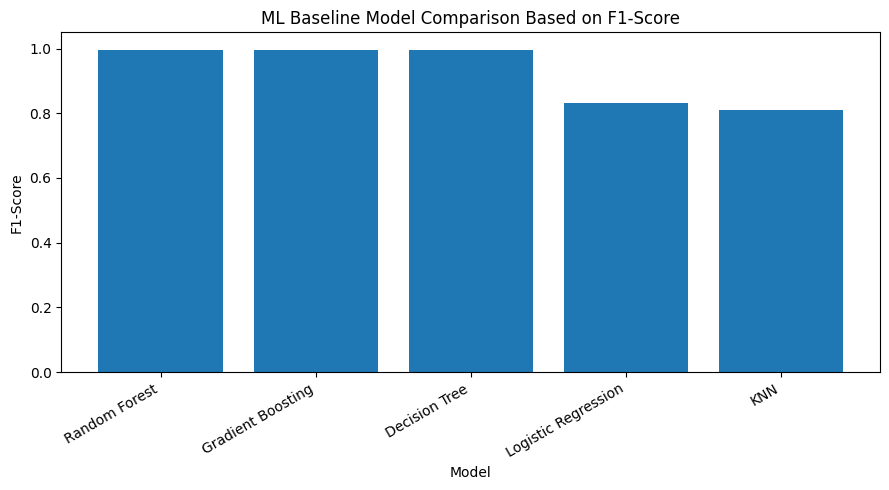

In [ ]:
# ============================================================
# 6. MODEL COMPARISON CHART
# ============================================================

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["F1-Score"])
plt.title("ML Baseline Model Comparison Based on F1-Score")
plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

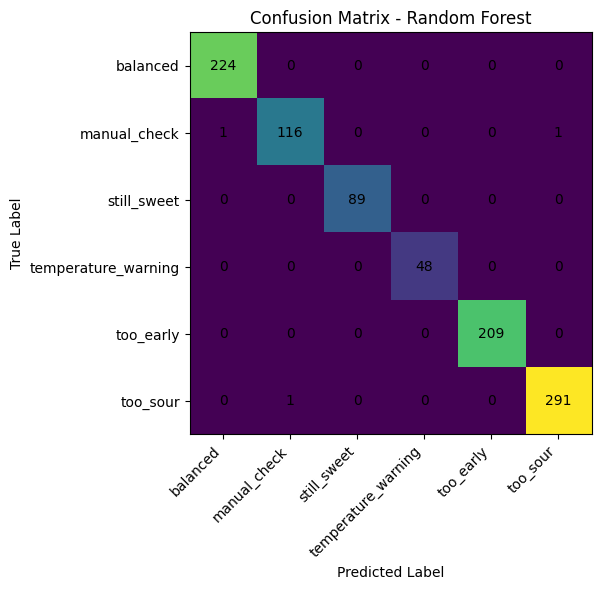

Best model: Random Forest


In [ ]:
# ============================================================
# 7. CONFUSION MATRIX FOR BEST MODEL
# ============================================================

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(ticks=np.arange(len(target_names)), labels=target_names, rotation=45, ha="right")
plt.yticks(ticks=np.arange(len(target_names)), labels=target_names)

for i in range(len(target_names)):
    for j in range(len(target_names)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

print("Best model:", best_model_name)

In [ ]:
# ============================================================
# GROUP SHUFFLE SPLIT BY batch_id
# ============================================================

print("Dataset shape:", df.shape)
print("Unique batch:", df["batch_id"].nunique())
print("Expected unique batch:", 7 * 50)

data = df.copy()

label_encoders = {}

categorical_cols = ["recipe_id", "recipe_name", "tea_type", "risk_flag"]
target_col = "expected_status"

for col in categorical_cols + [target_col]:
    encoder = LabelEncoder()
    data[col + "_encoded"] = encoder.fit_transform(data[col])
    label_encoders[col] = encoder

features = [
    "recipe_id_encoded",
    "tea_type_encoded",
    "sugar_g_per_l",
    "starter_ml",
    "water_volume_l",
    "day",
    "room_temp_c",
    "humidity_percent",
    "ph",
    "brix"
]

X = data[features]
y = data[target_col + "_encoded"]
groups = data["batch_id"]

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_groups = groups.iloc[train_idx]
test_groups = groups.iloc[test_idx]

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTrain unique batch:", train_groups.nunique())
print("Test unique batch:", test_groups.nunique())

overlap_batches = set(train_groups.unique()).intersection(set(test_groups.unique()))

print("\nOverlapping batch_id:", len(overlap_batches))

if len(overlap_batches) == 0:
    print("Aman: tidak ada batch yang bocor antara train dan test.")
else:
    print("Bahaya: ada batch yang muncul di train dan test.")

Dataset shape: (4900, 16)
Unique batch: 350
Expected unique batch: 350
Train shape: (3920, 10)
Test shape: (980, 10)

Train unique batch: 280
Test unique batch: 70

Overlapping batch_id: 0
Aman: tidak ada batch yang bocor antara train dan test.


In [ ]:
# ============================================================
# CHECK LABEL DISTRIBUTION AFTER GROUP SPLIT
# ============================================================

train_status = data.iloc[train_idx]["expected_status"].value_counts(normalize=True).sort_index()
test_status = data.iloc[test_idx]["expected_status"].value_counts(normalize=True).sort_index()

distribution_check = pd.DataFrame({
    "train_distribution": train_status,
    "test_distribution": test_status
}).fillna(0)

print(distribution_check)

                     train_distribution  test_distribution
expected_status                                           
balanced                       0.220408           0.260204
manual_check                   0.119898           0.124490
still_sweet                    0.087500           0.103061
temperature_warning            0.054337           0.024490
too_early                      0.215306           0.207143
too_sour                       0.302551           0.280612


In [ ]:
# ============================================================
# TRAIN ML BASELINE MODELS WITH GROUP SPLIT
# ============================================================

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=8
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        max_depth=12
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=7))
    ]),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(max_iter=1500))
    ])
}

results = []

target_names = label_encoders[target_col].classes_

for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results.append({
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })

    print("=" * 70)
    print(model_name)
    print("=" * 70)
    print(classification_report(
        y_test,
        y_pred,
        target_names=target_names,
        zero_division=0
    ))

results_group_df = pd.DataFrame(results)
results_group_df = results_group_df.sort_values(by="F1-Score", ascending=False)

print("\nGROUP SPLIT MODEL COMPARISON")
display(results_group_df)

results_group_df.to_csv("scoby_watch_group_split_ml_results.csv", index=False)

Decision Tree
                     precision    recall  f1-score   support

           balanced       0.99      1.00      0.99       255
       manual_check       1.00      0.96      0.98       122
        still_sweet       0.98      0.99      0.99       101
temperature_warning       1.00      1.00      1.00        24
          too_early       0.99      1.00      0.99       203
           too_sour       1.00      1.00      1.00       275

           accuracy                           0.99       980
          macro avg       0.99      0.99      0.99       980
       weighted avg       0.99      0.99      0.99       980

Random Forest
                     precision    recall  f1-score   support

           balanced       0.99      1.00      1.00       255
       manual_check       1.00      0.98      0.99       122
        still_sweet       0.98      0.99      0.99       101
temperature_warning       1.00      1.00      1.00        24
          too_early       1.00      1.00      1.00   

,Model,Accuracy,Precision,Recall,F1-Score
2,Gradient Boosting,0.995918,0.995958,0.995918,0.995921
1,Random Forest,0.994898,0.994934,0.994898,0.994890
0,Decision Tree,0.992857,0.992930,0.992857,0.992826
4,Logistic Regression,0.824490,0.818069,0.824490,0.816906
3,KNN,0.803061,0.796012,0.803061,0.790718


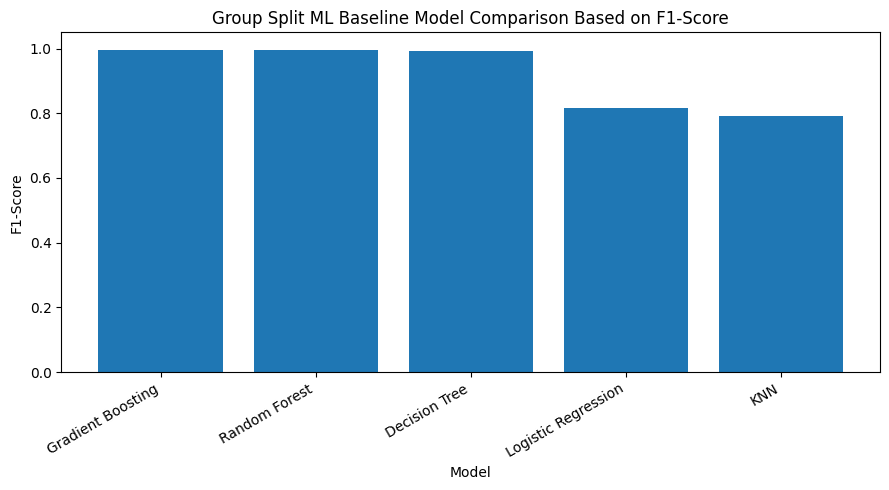

In [ ]:
# ============================================================
# GROUP SPLIT MODEL COMPARISON CHART
# ============================================================

plt.figure(figsize=(9, 5))
plt.bar(results_group_df["Model"], results_group_df["F1-Score"])
plt.title("Group Split ML Baseline Model Comparison Based on F1-Score")
plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

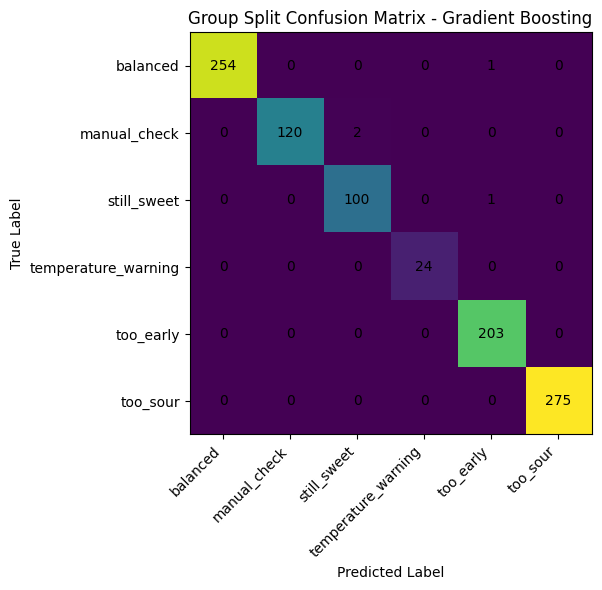

Best group split model: Gradient Boosting


In [ ]:
# ============================================================
# CONFUSION MATRIX FOR BEST GROUP SPLIT MODEL
# ============================================================

best_model_name = results_group_df.iloc[0]["Model"]
best_model = models[best_model_name]

# Pastikan model terbaik sudah fit
best_model.fit(X_train, y_train)

y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.title(f"Group Split Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    ticks=np.arange(len(target_names)),
    labels=target_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(target_names)),
    labels=target_names
)

for i in range(len(target_names)):
    for j in range(len(target_names)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

print("Best group split model:", best_model_name)

In [ ]:
# ============================================================
# SAVE BEST MODEL AND ENCODERS
# ============================================================

best_model.fit(X_train, y_train)

joblib.dump(best_model, "scoby_watch_best_group_split_model.pkl")
joblib.dump(label_encoders, "scoby_watch_label_encoders.pkl")
joblib.dump(features, "scoby_watch_feature_columns.pkl")

print("Saved model: scoby_watch_best_group_split_model.pkl")
print("Saved encoders: scoby_watch_label_encoders.pkl")
print("Saved features: scoby_watch_feature_columns.pkl")

Saved model: scoby_watch_best_group_split_model.pkl
Saved encoders: scoby_watch_label_encoders.pkl
Saved features: scoby_watch_feature_columns.pkl


In [ ]:
# ============================================================
# CELL - BASIC DATASET SANITY CHECK
# ============================================================

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nUnique recipes:", df["recipe_id"].nunique())
print("Unique batches:", df["batch_id"].nunique())
print("Unique days:", sorted(df["day"].unique()))

print("\nRows per recipe:")
display(df["recipe_id"].value_counts().sort_index())

print("\nRows per batch summary:")
batch_row_counts = df.groupby("batch_id").size()
display(batch_row_counts.describe())

print("\nStatus distribution:")
display(df["expected_status"].value_counts())

print("\nStatus distribution percentage:")
display((df["expected_status"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (4900, 16)

Columns:
['batch_id', 'recipe_id', 'recipe_name', 'tea_type', 'sugar_g_per_l', 'starter_ml', 'water_volume_l', 'day', 'room_temp_c', 'humidity_percent', 'ph', 'brix', 'expected_status', 'recommendation', 'rule_triggered', 'risk_flag']

Missing values:


,0
batch_id,0
recipe_id,0
recipe_name,0
tea_type,0
sugar_g_per_l,0
starter_ml,0
water_volume_l,0
day,0
room_temp_c,0
humidity_percent,0



Duplicate rows:
0

Unique recipes: 7
Unique batches: 350
Unique days: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]

Rows per recipe:


,count
recipe_id,
R1,700
R2,700
R3,700
R4,700
R5,700
R6,700
R7,700



Rows per batch summary:


,0
count,350.0
mean,14.0
std,0.0
min,14.0
25%,14.0
50%,14.0
75%,14.0
max,14.0



Status distribution:


,count
expected_status,
too_sour,1461
balanced,1119
too_early,1047
manual_check,592
still_sweet,444
temperature_warning,237



Status distribution percentage:


,proportion
expected_status,
too_sour,29.82
balanced,22.84
too_early,21.37
manual_check,12.08
still_sweet,9.06
temperature_warning,4.84


In [ ]:
# ============================================================
# CELL - SENSOR RANGE CHECK
# ============================================================

sensor_cols = [
    "room_temp_c",
    "humidity_percent",
    "ph",
    "brix",
    "sugar_g_per_l",
    "starter_ml"
]

range_summary = df[sensor_cols].describe().T

display(range_summary)

# Check out-of-range values based on simulation assumptions
range_issues = {
    "temp_below_15": (df["room_temp_c"] < 15).sum(),
    "temp_above_35": (df["room_temp_c"] > 35).sum(),
    "humidity_below_40": (df["humidity_percent"] < 40).sum(),
    "humidity_above_90": (df["humidity_percent"] > 90).sum(),
    "ph_below_2_4": (df["ph"] < 2.4).sum(),
    "ph_above_5_0": (df["ph"] > 5.0).sum(),
    "brix_below_1_5": (df["brix"] < 1.5).sum(),
    "brix_above_14": (df["brix"] > 14.0).sum()
}

range_issues_df = pd.DataFrame(
    list(range_issues.items()),
    columns=["check", "count"]
)

display(range_issues_df)

,count,mean,std,min,25%,50%,75%,max
room_temp_c,4900.0,25.425769,2.414248,17.54,23.8800,25.310,26.8300,34.30
humidity_percent,4900.0,67.876522,7.932361,40.00,62.3875,67.810,73.4425,90.00
ph,4900.0,3.686388,0.609790,2.40,3.2400,3.750,4.1700,5.00
brix,4900.0,6.514943,2.721378,1.50,4.5700,6.760,8.5300,13.99
sugar_g_per_l,4900.0,80.557486,11.584391,53.05,76.4200,81.100,84.9900,108.66
starter_ml,4900.0,151.879600,37.674526,67.49,137.7100,149.845,163.3300,261.15


,check,count
0,temp_below_15,0
1,temp_above_35,0
2,humidity_below_40,0
3,humidity_above_90,0
4,ph_below_2_4,0
5,ph_above_5_0,0
6,brix_below_1_5,0
7,brix_above_14,0


,day,ph
0,1,4.506943
1,2,4.381400
2,3,4.251971
3,4,4.117229
4,5,3.993971
5,6,3.859886
6,7,3.737086
7,8,3.610943
8,9,3.469829
9,10,3.350229


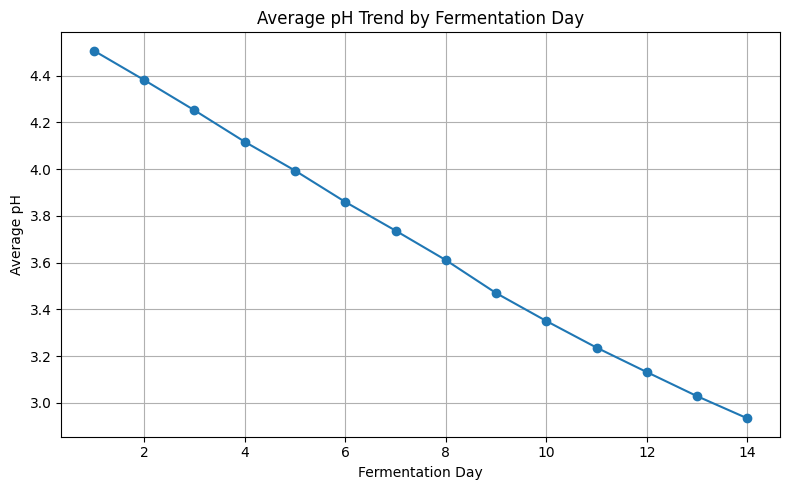

In [ ]:
# ============================================================
# CELL - AVERAGE pH TREND BY DAY
# ============================================================

ph_by_day = df.groupby("day")["ph"].mean().reset_index()

display(ph_by_day)

plt.figure(figsize=(8, 5))
plt.plot(ph_by_day["day"], ph_by_day["ph"], marker="o")
plt.title("Average pH Trend by Fermentation Day")
plt.xlabel("Fermentation Day")
plt.ylabel("Average pH")
plt.grid(True)
plt.tight_layout()
plt.show()

,day,brix
0,1,9.589286
1,2,9.107457
2,3,8.648400
3,4,8.120343
4,5,7.625114
5,6,7.128229
6,7,6.634543
7,8,6.183657
8,9,5.694000
9,10,5.251371


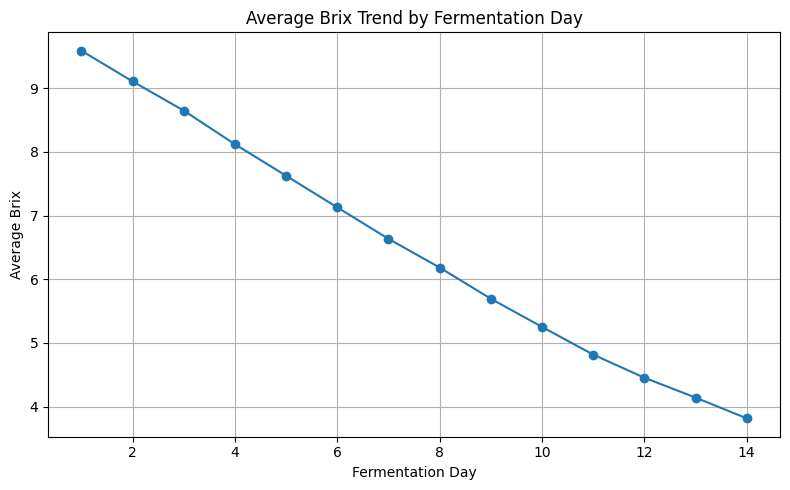

In [ ]:
# ============================================================
# CELL - AVERAGE BRIX TREND BY DAY
# ============================================================

brix_by_day = df.groupby("day")["brix"].mean().reset_index()

display(brix_by_day)

plt.figure(figsize=(8, 5))
plt.plot(brix_by_day["day"], brix_by_day["brix"], marker="o")
plt.title("Average Brix Trend by Fermentation Day")
plt.xlabel("Fermentation Day")
plt.ylabel("Average Brix")
plt.grid(True)
plt.tight_layout()
plt.show()

,recipe_id,day,ph
0,R1,1,4.5412
1,R1,2,4.4318
2,R1,3,4.3088
3,R1,4,4.1882
4,R1,5,4.0596


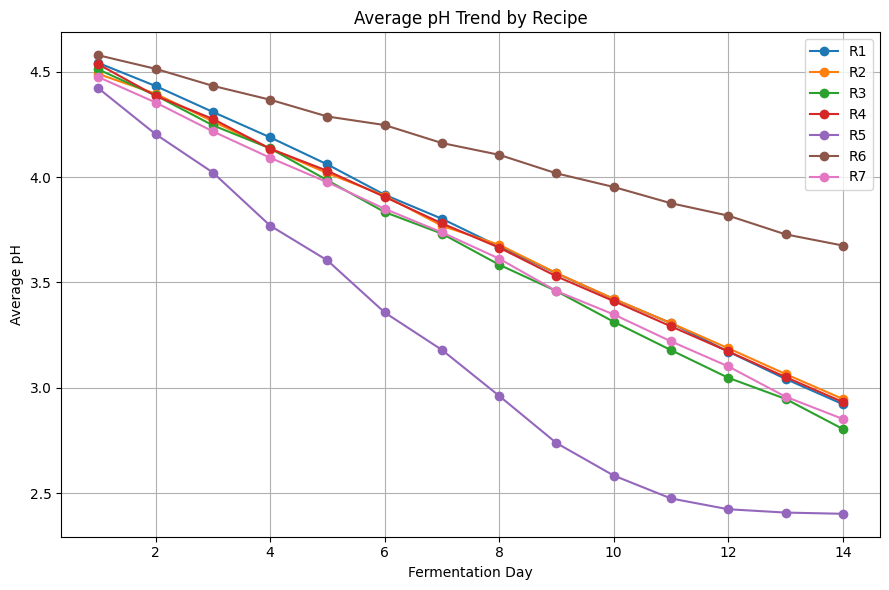

In [ ]:
# ============================================================
# CELL - AVERAGE pH TREND BY RECIPE
# ============================================================

ph_recipe_day = (
    df.groupby(["recipe_id", "day"])["ph"]
    .mean()
    .reset_index()
)

display(ph_recipe_day.head())

plt.figure(figsize=(9, 6))

for recipe_id in sorted(df["recipe_id"].unique()):
    temp = ph_recipe_day[ph_recipe_day["recipe_id"] == recipe_id]
    plt.plot(temp["day"], temp["ph"], marker="o", label=recipe_id)

plt.title("Average pH Trend by Recipe")
plt.xlabel("Fermentation Day")
plt.ylabel("Average pH")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

,recipe_id,day,brix
0,R1,1,9.5188
1,R1,2,9.0862
2,R1,3,8.6072
3,R1,4,8.1044
4,R1,5,7.7012


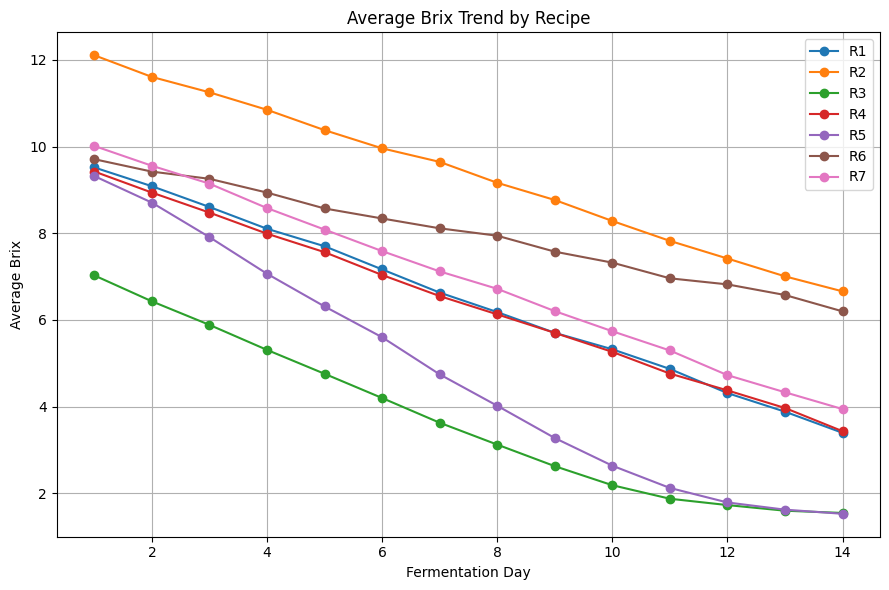

In [ ]:
# ============================================================
# CELL - AVERAGE BRIX TREND BY RECIPE
# ============================================================

brix_recipe_day = (
    df.groupby(["recipe_id", "day"])["brix"]
    .mean()
    .reset_index()
)

display(brix_recipe_day.head())

plt.figure(figsize=(9, 6))

for recipe_id in sorted(df["recipe_id"].unique()):
    temp = brix_recipe_day[brix_recipe_day["recipe_id"] == recipe_id]
    plt.plot(temp["day"], temp["brix"], marker="o", label=recipe_id)

plt.title("Average Brix Trend by Recipe")
plt.xlabel("Fermentation Day")
plt.ylabel("Average Brix")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

expected_status,balanced,manual_check,still_sweet,temperature_warning,too_early,too_sour
day,,,,,,
1,0,21,0,17,312,0
2,0,76,0,17,257,0
3,0,140,0,20,186,4
4,0,203,0,17,117,13
5,126,1,105,15,69,34
6,147,10,87,17,39,50
7,149,6,73,17,23,82
8,156,7,59,15,14,99
9,141,13,49,17,13,117


expected_status,balanced,manual_check,still_sweet,temperature_warning,too_early,too_sour
day,,,,,,
1,0.00,6.00,0.00,4.86,89.14,0.00
2,0.00,21.71,0.00,4.86,73.43,0.00
3,0.00,40.00,0.00,5.71,53.14,1.14
4,0.00,58.00,0.00,4.86,33.43,3.71
5,36.00,0.29,30.00,4.29,19.71,9.71
6,42.00,2.86,24.86,4.86,11.14,14.29
7,42.57,1.71,20.86,4.86,6.57,23.43
8,44.57,2.00,16.86,4.29,4.00,28.29
9,40.29,3.71,14.00,4.86,3.71,33.43


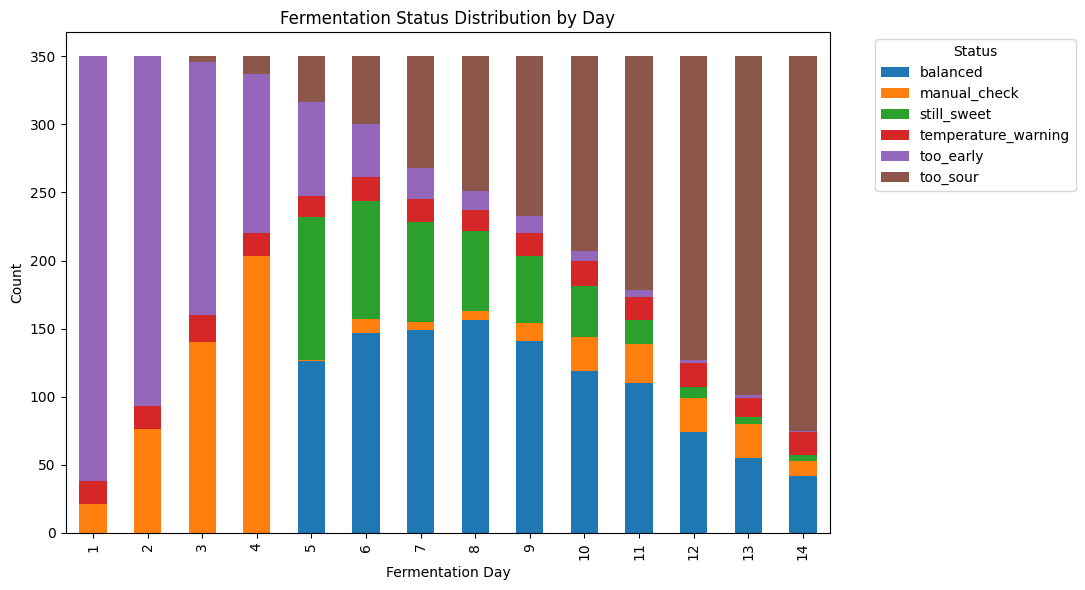

In [ ]:
# ============================================================
# CELL - STATUS DISTRIBUTION BY DAY
# ============================================================

status_by_day = pd.crosstab(
    df["day"],
    df["expected_status"]
)

display(status_by_day)

status_by_day_percent = pd.crosstab(
    df["day"],
    df["expected_status"],
    normalize="index"
) * 100

display(status_by_day_percent.round(2))

status_by_day.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Fermentation Status Distribution by Day")
plt.xlabel("Fermentation Day")
plt.ylabel("Count")
plt.legend(title="Status", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

expected_status,balanced,manual_check,still_sweet,temperature_warning,too_early,too_sour
recipe_id,,,,,,
R1,227,66,33,32,151,191
R2,83,111,257,42,141,66
R3,21,54,0,38,133,454
R4,240,80,18,17,153,192
R5,75,142,2,24,73,384
R6,245,29,84,65,269,8
R7,228,110,50,19,127,166


expected_status,balanced,manual_check,still_sweet,temperature_warning,too_early,too_sour
recipe_id,,,,,,
R1,32.43,9.43,4.71,4.57,21.57,27.29
R2,11.86,15.86,36.71,6.00,20.14,9.43
R3,3.00,7.71,0.00,5.43,19.00,64.86
R4,34.29,11.43,2.57,2.43,21.86,27.43
R5,10.71,20.29,0.29,3.43,10.43,54.86
R6,35.00,4.14,12.00,9.29,38.43,1.14
R7,32.57,15.71,7.14,2.71,18.14,23.71


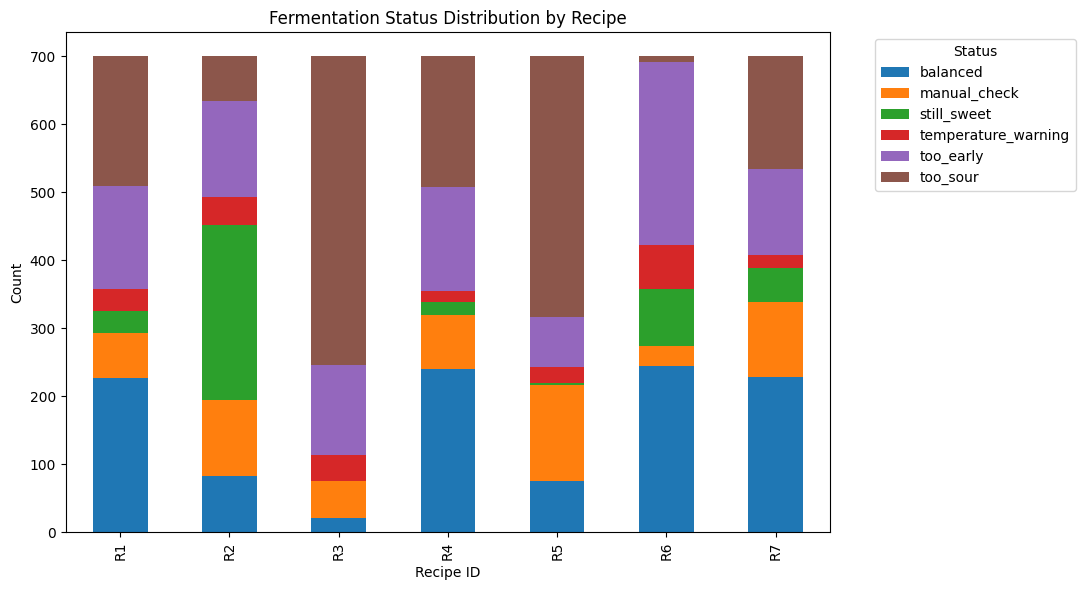

In [ ]:
# ============================================================
# CELL - STATUS DISTRIBUTION BY RECIPE
# ============================================================

status_by_recipe = pd.crosstab(
    df["recipe_id"],
    df["expected_status"]
)

display(status_by_recipe)

status_by_recipe_percent = pd.crosstab(
    df["recipe_id"],
    df["expected_status"],
    normalize="index"
) * 100

display(status_by_recipe_percent.round(2))

status_by_recipe.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Fermentation Status Distribution by Recipe")
plt.xlabel("Recipe ID")
plt.ylabel("Count")
plt.legend(title="Status", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL - MONOTONIC TREND CHECK PER BATCH
# ============================================================

trend_rows = []

for batch_id, batch_df in df.groupby("batch_id"):
    batch_df = batch_df.sort_values("day")

    ph_slope = np.polyfit(batch_df["day"], batch_df["ph"], 1)[0]
    brix_slope = np.polyfit(batch_df["day"], batch_df["brix"], 1)[0]

    trend_rows.append({
        "batch_id": batch_id,
        "recipe_id": batch_df["recipe_id"].iloc[0],
        "ph_slope": ph_slope,
        "brix_slope": brix_slope,
        "ph_trend_ok": ph_slope < 0,
        "brix_trend_ok": brix_slope < 0
    })

trend_df = pd.DataFrame(trend_rows)

print("Total batches:", trend_df.shape[0])

print("\npH trend check:")
display(trend_df["ph_trend_ok"].value_counts())

print("\nBrix trend check:")
display(trend_df["brix_trend_ok"].value_counts())

print("\nBatches with suspicious pH trend:")
display(trend_df[trend_df["ph_trend_ok"] == False])

print("\nBatches with suspicious Brix trend:")
display(trend_df[trend_df["brix_trend_ok"] == False])

Total batches: 350

pH trend check:


,count
ph_trend_ok,
True,350



Brix trend check:


,count
brix_trend_ok,
True,350



Batches with suspicious pH trend:


,batch_id,recipe_id,ph_slope,brix_slope,ph_trend_ok,brix_trend_ok



Batches with suspicious Brix trend:


,batch_id,recipe_id,ph_slope,brix_slope,ph_trend_ok,brix_trend_ok


In [ ]:
# ============================================================
# CELL - STATUS TRANSITION SAMPLE PER BATCH
# ============================================================

sample_batches = df["batch_id"].drop_duplicates().head(10)

for batch_id in sample_batches:
    temp = df[df["batch_id"] == batch_id].sort_values("day")

    print("=" * 80)
    print("Batch:", batch_id)
    print("Recipe:", temp["recipe_id"].iloc[0], "-", temp["recipe_name"].iloc[0])
    print(temp[["day", "room_temp_c", "ph", "brix", "expected_status", "rule_triggered"]].to_string(index=False))


Batch: KB-R1-001
Recipe: R1 - Standard Black Tea
 day  room_temp_c   ph  brix expected_status                     rule_triggered
   1        25.86 4.52 10.19       too_early             R3_early_acidity_stage
   2        24.34 4.49  9.63       too_early             R3_early_acidity_stage
   3        25.97 4.24  9.06       too_early             R3_early_acidity_stage
   4        25.82 4.34  9.44       too_early             R3_early_acidity_stage
   5        26.39 3.98  9.22     still_sweet        R6_sweet_fermentation_stage
   6        26.51 3.82  8.51     still_sweet        R6_sweet_fermentation_stage
   7        25.90 3.74  8.29     still_sweet        R6_sweet_fermentation_stage
   8        25.35 3.81  8.14     still_sweet        R6_sweet_fermentation_stage
   9        26.46 3.41  6.93        balanced          R10_balanced_ready_window
  10        26.88 3.25  6.76        balanced          R10_balanced_ready_window
  11        25.45 3.25  6.90        balanced          R10_balanced_read

,count
rule_triggered,
R4_R5_over_acidic_or_low_sweetness,1461
R3_early_acidity_stage,1047
R10_balanced_ready_window,846
R6_sweet_fermentation_stage,444
R9_early_day_manual_check,438
R7_balanced_but_early,273
R1_high_temperature_warning,237
R8_ambiguous_condition,149
R2_low_temperature_slow_fermentation,5


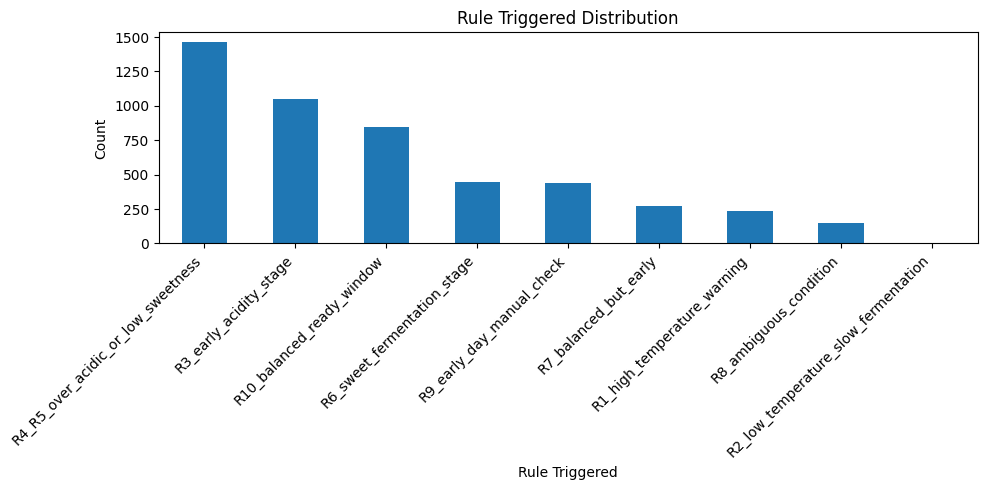

In [ ]:
# ============================================================
# CELL - RULE TRIGGERED DISTRIBUTION
# ============================================================

rule_distribution = df["rule_triggered"].value_counts()

display(rule_distribution)

plt.figure(figsize=(10, 5))
rule_distribution.plot(kind="bar")
plt.title("Rule Triggered Distribution")
plt.xlabel("Rule Triggered")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL - EXPORT SANITY CHECK TABLES
# ============================================================

status_by_day.to_csv("sanity_status_by_day.csv")
status_by_recipe.to_csv("sanity_status_by_recipe.csv")
ph_by_day.to_csv("sanity_ph_by_day.csv", index=False)
brix_by_day.to_csv("sanity_brix_by_day.csv", index=False)
trend_df.to_csv("sanity_batch_trend_check.csv", index=False)
rule_distribution.to_csv("sanity_rule_distribution.csv")

print("Sanity check files exported:")
print("- sanity_status_by_day.csv")
print("- sanity_status_by_recipe.csv")
print("- sanity_ph_by_day.csv")
print("- sanity_brix_by_day.csv")
print("- sanity_batch_trend_check.csv")
print("- sanity_rule_distribution.csv")

Sanity check files exported:
- sanity_status_by_day.csv
- sanity_status_by_recipe.csv
- sanity_ph_by_day.csv
- sanity_brix_by_day.csv
- sanity_batch_trend_check.csv
- sanity_rule_distribution.csv


In [ ]:
# ============================================================
# CELL 1 - LOAD BEST MODEL, ENCODERS, AND FEATURES
# ============================================================

import joblib
import pandas as pd
import numpy as np

best_model = joblib.load("scoby_watch_best_group_split_model.pkl")
label_encoders = joblib.load("scoby_watch_label_encoders.pkl")
features = joblib.load("scoby_watch_feature_columns.pkl")

print("Model loaded:", best_model)
print("Features:", features)
print("Available encoders:", list(label_encoders.keys()))

Model loaded: GradientBoostingClassifier(random_state=42)
Features: ['recipe_id_encoded', 'tea_type_encoded', 'sugar_g_per_l', 'starter_ml', 'water_volume_l', 'day', 'room_temp_c', 'humidity_percent', 'ph', 'brix']
Available encoders: ['recipe_id', 'recipe_name', 'tea_type', 'risk_flag', 'expected_status']


In [ ]:
# ============================================================
# CELL 2 - PREPARE INPUT FOR ML MODEL
# ============================================================

def prepare_ml_input(input_data, label_encoders, features):
    """
    Mengubah input kombucha menjadi format fitur yang bisa dibaca model ML.
    """

    data = input_data.copy()

    # Encode categorical columns
    data["recipe_id_encoded"] = label_encoders["recipe_id"].transform([data["recipe_id"]])[0]
    data["tea_type_encoded"] = label_encoders["tea_type"].transform([data["tea_type"]])[0]

    row = pd.DataFrame([{
        "recipe_id_encoded": data["recipe_id_encoded"],
        "tea_type_encoded": data["tea_type_encoded"],
        "sugar_g_per_l": data["sugar_g_per_l"],
        "starter_ml": data["starter_ml"],
        "water_volume_l": data["water_volume_l"],
        "day": data["day"],
        "room_temp_c": data["room_temp_c"],
        "humidity_percent": data["humidity_percent"],
        "ph": data["ph"],
        "brix": data["brix"]
    }])

    return row[features]

In [ ]:
# ============================================================
# CELL 2 - PREPARE INPUT FOR ML MODEL
# ============================================================

def prepare_ml_input(input_data, label_encoders, features):
    """
    Mengubah input kombucha menjadi format fitur yang bisa dibaca model ML.
    """

    data = input_data.copy()

    # Encode categorical columns
    data["recipe_id_encoded"] = label_encoders["recipe_id"].transform([data["recipe_id"]])[0]
    data["tea_type_encoded"] = label_encoders["tea_type"].transform([data["tea_type"]])[0]

    row = pd.DataFrame([{
        "recipe_id_encoded": data["recipe_id_encoded"],
        "tea_type_encoded": data["tea_type_encoded"],
        "sugar_g_per_l": data["sugar_g_per_l"],
        "starter_ml": data["starter_ml"],
        "water_volume_l": data["water_volume_l"],
        "day": data["day"],
        "room_temp_c": data["room_temp_c"],
        "humidity_percent": data["humidity_percent"],
        "ph": data["ph"],
        "brix": data["brix"]
    }])

    return row[features]

In [ ]:
# ============================================================
# CELL 4 - HYBRID DECISION LAYER
# ============================================================

def hybrid_decision_layer(rule_result, ml_result, confidence_threshold=0.70):
    """
    Menggabungkan hasil Rule-Based Model dan ML Model.
    Rule-based dipakai sebagai anchor, ML dipakai sebagai confirmation layer.
    """

    rule_status = rule_result["status"]
    ml_status = ml_result["ml_status"]
    ml_confidence = ml_result["ml_confidence"]

    # 1. Temperature warning selalu menang
    if rule_status == "temperature_warning":
        final_status = "temperature_warning"
        decision_reason = "Rule-based temperature warning has priority over ML prediction."

    # 2. Kalau confidence ML rendah, jangan percaya diri
    elif ml_confidence is not None and ml_confidence < confidence_threshold:
        final_status = "manual_check"
        decision_reason = "ML confidence is below threshold; manual inspection is required."

    # 3. Kalau rule dan ML setuju, final ikut status itu
    elif rule_status == ml_status:
        final_status = rule_status
        decision_reason = "Rule-based and ML model agree on the same fermentation status."

    # 4. Kalau salah satu bilang too_sour tapi yang lain beda, jangan langsung ambil keputusan
    elif rule_status == "too_sour" or ml_status == "too_sour":
        final_status = "manual_check"
        decision_reason = "Conflict involving too_sour status; manual inspection is required."

    # 5. Kalau konflik lain, manual check
    else:
        final_status = "manual_check"
        decision_reason = "Rule-based and ML model disagree; manual inspection is required."

    return {
        "rule_status": rule_status,
        "ml_status": ml_status,
        "ml_confidence": ml_confidence,
        "final_status": final_status,
        "decision_reason": decision_reason,
        "rule_triggered": rule_result["rule_triggered"],
        "risk_flag": rule_result["risk_flag"],
        "recommendation": rule_result["recommendation"]
    }

In [ ]:
# ============================================================
# PREPARE INPUT + ML PREDICTION FUNCTION
# ============================================================

def prepare_ml_input(input_data, label_encoders, features):
    """
    Mengubah input kombucha menjadi format fitur yang bisa dibaca model ML.
    """

    data = input_data.copy()

    # Encode categorical columns
    data["recipe_id_encoded"] = label_encoders["recipe_id"].transform([data["recipe_id"]])[0]
    data["tea_type_encoded"] = label_encoders["tea_type"].transform([data["tea_type"]])[0]

    row = pd.DataFrame([{
        "recipe_id_encoded": data["recipe_id_encoded"],
        "tea_type_encoded": data["tea_type_encoded"],
        "sugar_g_per_l": data["sugar_g_per_l"],
        "starter_ml": data["starter_ml"],
        "water_volume_l": data["water_volume_l"],
        "day": data["day"],
        "room_temp_c": data["room_temp_c"],
        "humidity_percent": data["humidity_percent"],
        "ph": data["ph"],
        "brix": data["brix"]
    }])

    return row[features]


def predict_ml_status(input_data, model, label_encoders, features):
    """
    Menghasilkan prediksi status dari model ML dan confidence score.
    """

    X_input = prepare_ml_input(
        input_data=input_data,
        label_encoders=label_encoders,
        features=features
    )

    pred_encoded = model.predict(X_input)[0]

    pred_status = label_encoders["expected_status"].inverse_transform([pred_encoded])[0]

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_input)[0]
        confidence = float(np.max(probabilities))
    else:
        confidence = None

    return {
        "ml_status": pred_status,
        "ml_confidence": confidence
    }

In [ ]:
# ============================================================
# HYBRID DECISION LAYER
# ============================================================

def hybrid_decision_layer(rule_result, ml_result, confidence_threshold=0.70):
    """
    Menggabungkan hasil Rule-Based Model dan ML Model.
    Rule-based dipakai sebagai anchor, ML sebagai confirmation layer.
    """

    rule_status = rule_result["status"]
    ml_status = ml_result["ml_status"]
    ml_confidence = ml_result["ml_confidence"]

    if rule_status == "temperature_warning":
        final_status = "temperature_warning"
        decision_reason = "Rule-based temperature warning has priority over ML prediction."

    elif ml_confidence < confidence_threshold:
        final_status = "manual_check"
        decision_reason = "ML confidence is below threshold; manual inspection is required."

    elif rule_status == ml_status:
        final_status = rule_status
        decision_reason = "Rule-based and ML model agree on the same fermentation status."

    elif rule_status == "too_sour" or ml_status == "too_sour":
        final_status = "manual_check"
        decision_reason = "Conflict involving too_sour status; manual inspection is required."

    else:
        final_status = "manual_check"
        decision_reason = "Rule-based and ML model disagree; manual inspection is required."

    return {
        "rule_status": rule_status,
        "ml_status": ml_status,
        "ml_confidence": ml_confidence,
        "final_status": final_status,
        "decision_reason": decision_reason,
        "rule_triggered": rule_result["rule_triggered"],
        "risk_flag": rule_result["risk_flag"],
        "recommendation": generate_final_recommendation(final_status)
    }

In [ ]:
def generate_final_recommendation(final_status):
    recommendations = {
        "too_early": "Continue fermentation and check again within 24 hours.",
        "still_sweet": "Continue fermentation or start taste testing.",
        "balanced": "Start taste testing and consider bottling if the flavor matches preference.",
        "too_sour": "The batch may be over-fermented. Consider using it as starter or dilute based on taste preference.",
        "temperature_warning": "Move the batch to a cooler area and monitor closely.",
        "manual_check": "Perform manual inspection using visual check, aroma, pH, Brix, and taste evaluation before making a decision."
    }

    return recommendations.get(
        final_status,
        "Manual inspection is recommended before making a decision."
    )

In [ ]:
# ============================================================
# CELL 5 - TEST HYBRID DECISION WITH ONE SAMPLE
# ============================================================

sample_input = {
    "recipe_id": "R1",
    "tea_type": "black_tea",
    "sugar_g_per_l": 80,
    "starter_ml": 150,
    "water_volume_l": 1.0,
    "day": 7,
    "room_temp_c": 25.5,
    "humidity_percent": 68,
    "ph": 3.5,
    "brix": 6.5
}

rule_result = classify_kombucha_status(
    temperature_c=sample_input["room_temp_c"],
    humidity_percent=sample_input["humidity_percent"],
    ph=sample_input["ph"],
    brix=sample_input["brix"],
    fermentation_day=sample_input["day"]
)

ml_result = predict_ml_status(
    input_data=sample_input,
    model=best_model,
    label_encoders=label_encoders,
    features=features
)

hybrid_result = hybrid_decision_layer(
    rule_result=rule_result,
    ml_result=ml_result,
    confidence_threshold=0.70
)

hybrid_result


{'rule_status': 'balanced',
 'ml_status': 'balanced',
 'ml_confidence': 0.999820415147993,
 'final_status': 'balanced',
 'decision_reason': 'Rule-based and ML model agree on the same fermentation status.',
 'rule_triggered': 'R10_balanced_ready_window',
 'risk_flag': 'normal',
 'recommendation': 'Start taste testing and consider bottling if the flavor matches preference.'}

In [ ]:
# ============================================================
# CELL 6 - TEST MULTIPLE HYBRID SCENARIOS
# ============================================================

test_cases = [
    {
        "case_id": "TC-001",
        "recipe_id": "R1",
        "tea_type": "black_tea",
        "sugar_g_per_l": 80,
        "starter_ml": 150,
        "water_volume_l": 1.0,
        "day": 1,
        "room_temp_c": 25.0,
        "humidity_percent": 68,
        "ph": 4.6,
        "brix": 10.2
    },
    {
        "case_id": "TC-002",
        "recipe_id": "R1",
        "tea_type": "black_tea",
        "sugar_g_per_l": 80,
        "starter_ml": 150,
        "water_volume_l": 1.0,
        "day": 6,
        "room_temp_c": 25.5,
        "humidity_percent": 67,
        "ph": 3.7,
        "brix": 9.1
    },
    {
        "case_id": "TC-003",
        "recipe_id": "R1",
        "tea_type": "black_tea",
        "sugar_g_per_l": 80,
        "starter_ml": 150,
        "water_volume_l": 1.0,
        "day": 8,
        "room_temp_c": 25.2,
        "humidity_percent": 66,
        "ph": 3.5,
        "brix": 6.4
    },
    {
        "case_id": "TC-004",
        "recipe_id": "R1",
        "tea_type": "black_tea",
        "sugar_g_per_l": 80,
        "starter_ml": 150,
        "water_volume_l": 1.0,
        "day": 12,
        "room_temp_c": 26.0,
        "humidity_percent": 70,
        "ph": 2.8,
        "brix": 4.5
    },
    {
        "case_id": "TC-005",
        "recipe_id": "R1",
        "tea_type": "black_tea",
        "sugar_g_per_l": 80,
        "starter_ml": 150,
        "water_volume_l": 1.0,
        "day": 7,
        "room_temp_c": 31.5,
        "humidity_percent": 72,
        "ph": 3.6,
        "brix": 6.8
    }
]

hybrid_rows = []

for case in test_cases:
    rule_result = classify_kombucha_status(
        temperature_c=case["room_temp_c"],
        humidity_percent=case["humidity_percent"],
        ph=case["ph"],
        brix=case["brix"],
        fermentation_day=case["day"]
    )

    ml_result = predict_ml_status(
        input_data=case,
        model=best_model,
        label_encoders=label_encoders,
        features=features
    )

    hybrid_result = hybrid_decision_layer(
        rule_result=rule_result,
        ml_result=ml_result,
        confidence_threshold=0.70
    )

    hybrid_rows.append({
        "case_id": case["case_id"],
        "day": case["day"],
        "temp": case["room_temp_c"],
        "ph": case["ph"],
        "brix": case["brix"],
        "rule_status": hybrid_result["rule_status"],
        "ml_status": hybrid_result["ml_status"],
        "ml_confidence": hybrid_result["ml_confidence"],
        "final_status": hybrid_result["final_status"],
        "rule_triggered": hybrid_result["rule_triggered"],
        "decision_reason": hybrid_result["decision_reason"],
        "recommendation": hybrid_result["recommendation"]
    })

hybrid_test_df = pd.DataFrame(hybrid_rows)
display(hybrid_test_df)

hybrid_test_df.to_csv("scoby_watch_hybrid_decision_test.csv", index=False)

,case_id,day,temp,ph,brix,rule_status,ml_status,ml_confidence,final_status,rule_triggered,decision_reason,recommendation
0,TC-001,1,25.0,4.6,10.2,too_early,too_early,0.999984,too_early,R3_early_acidity_stage,Rule-based and ML model agree on the same ferm...,Continue fermentation and check again within 2...
1,TC-002,6,25.5,3.7,9.1,still_sweet,still_sweet,0.999628,still_sweet,R6_sweet_fermentation_stage,Rule-based and ML model agree on the same ferm...,Continue fermentation or start taste testing.
2,TC-003,8,25.2,3.5,6.4,balanced,balanced,0.999777,balanced,R10_balanced_ready_window,Rule-based and ML model agree on the same ferm...,Start taste testing and consider bottling if t...
3,TC-004,12,26.0,2.8,4.5,too_sour,too_sour,0.999968,too_sour,R4_R5_over_acidic_or_low_sweetness,Rule-based and ML model agree on the same ferm...,The batch may be over-fermented. Consider usin...
4,TC-005,7,31.5,3.6,6.8,temperature_warning,temperature_warning,0.999700,temperature_warning,R1_high_temperature_warning,Rule-based temperature warning has priority ov...,Move the batch to a cooler area and monitor cl...


In [ ]:
# Save hybrid decision test result
file_name = "scoby_watch_hybrid_decision_test.csv"

hybrid_test_df.to_csv(file_name, index=False)

print(f"File saved as: {file_name}")


File saved as: scoby_watch_hybrid_decision_test.csv


In [ ]:
import os

if os.path.exists(file_name):
    print("File exists. Ready to download.")
else:
    print("File not found. CSV was not created.")

File exists. Ready to download.


In [ ]:
# ============================================================
# FIX - ML PREDICTION FUNCTION
# ============================================================

def get_ml_prediction(model, input_features, label_encoders):
    """
    Mendapatkan prediksi status dan confidence dari model ML.
    """

    probs = model.predict_proba(input_features)[0]

    max_prob = np.max(probs)
    pred_idx = np.argmax(probs)

    predicted_label = label_encoders["expected_status"].inverse_transform([pred_idx])[0]

    return {
        "ml_status": predicted_label,
        "ml_confidence": float(max_prob)
    }

In [ ]:
# ============================================================
# CELL 6A - EDGE CASE TEST WITH REAL ML PREDICTION
# ============================================================

edge_test_scenarios = [
    {
        "case_id": "TC-006",
        "description": "Borderline Early Manual Check",
        "data": {
            "recipe_id": "R1",
            "tea_type": "black_tea",
            "sugar_g_per_l": 80,
            "starter_ml": 150,
            "water_volume_l": 1.0,
            "day": 4,
            "room_temp_c": 25.0,
            "humidity_percent": 68,
            "ph": 4.10,
            "brix": 7.20
        }
    },
    {
        "case_id": "TC-007",
        "description": "Borderline Balanced",
        "data": {
            "recipe_id": "R1",
            "tea_type": "black_tea",
            "sugar_g_per_l": 80,
            "starter_ml": 150,
            "water_volume_l": 1.0,
            "day": 7,
            "room_temp_c": 25.0,
            "humidity_percent": 66,
            "ph": 3.20,
            "brix": 5.00
        }
    },
    {
        "case_id": "TC-008",
        "description": "Low Brix Over-Fermentation",
        "data": {
            "recipe_id": "R1",
            "tea_type": "black_tea",
            "sugar_g_per_l": 80,
            "starter_ml": 150,
            "water_volume_l": 1.0,
            "day": 10,
            "room_temp_c": 25.5,
            "humidity_percent": 70,
            "ph": 3.35,
            "brix": 4.90
        }
    },
    {
        "case_id": "TC-009",
        "description": "Low Temperature Manual Check",
        "data": {
            "recipe_id": "R1",
            "tea_type": "black_tea",
            "sugar_g_per_l": 80,
            "starter_ml": 150,
            "water_volume_l": 1.0,
            "day": 8,
            "room_temp_c": 17.8,
            "humidity_percent": 68,
            "ph": 3.60,
            "brix": 6.70
        }
    },
    {
        "case_id": "TC-010",
        "description": "High Temperature Override",
        "data": {
            "recipe_id": "R1",
            "tea_type": "black_tea",
            "sugar_g_per_l": 80,
            "starter_ml": 150,
            "water_volume_l": 1.0,
            "day": 8,
            "room_temp_c": 31.2,
            "humidity_percent": 70,
            "ph": 3.50,
            "brix": 6.50
        }
    }
]

edge_rows = []

print("--- EDGE CASE HYBRID DECISION TEST ---\n")

for scenario in edge_test_scenarios:
    input_data = scenario["data"]

    rule_res = classify_kombucha_status(
        temperature_c=input_data["room_temp_c"],
        humidity_percent=input_data["humidity_percent"],
        ph=input_data["ph"],
        brix=input_data["brix"],
        fermentation_day=input_data["day"]
    )

    ml_features = prepare_ml_input(input_data, label_encoders, features)
    ml_res = get_ml_prediction(best_model, ml_features, label_encoders)

    hybrid_res = hybrid_decision_layer(
        rule_result=rule_res,
        ml_result=ml_res,
        confidence_threshold=0.70
    )

    edge_rows.append({
        "case_id": scenario["case_id"],
        "description": scenario["description"],
        "day": input_data["day"],
        "room_temp_c": input_data["room_temp_c"],
        "humidity_percent": input_data["humidity_percent"],
        "ph": input_data["ph"],
        "brix": input_data["brix"],
        "rule_status": hybrid_res["rule_status"],
        "ml_status": hybrid_res["ml_status"],
        "ml_confidence": hybrid_res["ml_confidence"],
        "final_status": hybrid_res["final_status"],
        "decision_reason": hybrid_res["decision_reason"],
        "recommendation": hybrid_res["recommendation"]
    })

edge_test_df = pd.DataFrame(edge_rows)

display(edge_test_df)

edge_file_name = "scoby_watch_hybrid_edge_case_test.csv"
edge_test_df.to_csv(edge_file_name, index=False)

print(f"Saved as: {edge_file_name}")

--- EDGE CASE HYBRID DECISION TEST ---



,case_id,description,day,room_temp_c,humidity_percent,ph,brix,rule_status,ml_status,ml_confidence,final_status,decision_reason,recommendation
0,TC-006,Borderline Early Manual Check,4,25.0,68,4.10,7.2,manual_check,manual_check,0.999457,manual_check,Rule-based and ML model agree on the same ferm...,"Perform manual inspection using visual check, ..."
1,TC-007,Borderline Balanced,7,25.0,66,3.20,5.0,balanced,balanced,0.901134,balanced,Rule-based and ML model agree on the same ferm...,Start taste testing and consider bottling if t...
2,TC-008,Low Brix Over-Fermentation,10,25.5,70,3.35,4.9,too_sour,too_sour,0.999923,too_sour,Rule-based and ML model agree on the same ferm...,The batch may be over-fermented. Consider usin...
3,TC-009,Low Temperature Manual Check,8,17.8,68,3.60,6.7,manual_check,manual_check,0.993838,manual_check,Rule-based and ML model agree on the same ferm...,"Perform manual inspection using visual check, ..."
4,TC-010,High Temperature Override,8,31.2,70,3.50,6.5,temperature_warning,temperature_warning,0.999731,temperature_warning,Rule-based temperature warning has priority ov...,Move the batch to a cooler area and monitor cl...


Saved as: scoby_watch_hybrid_edge_case_test.csv


In [ ]:
ml_features = prepare_ml_input(
    {
        "recipe_id": "R1",
        "tea_type": "black_tea",
        "sugar_g_per_l": 80,
        "starter_ml": 150,
        "water_volume_l": 1.0,
        "day": 7,
        "room_temp_c": 25.5,
        "humidity_percent": 68,
        "ph": 3.5,
        "brix": 6.5
    },
    label_encoders,
    features
)

ml_test = get_ml_prediction(best_model, ml_features, label_encoders)
ml_test

{'ml_status': 'balanced', 'ml_confidence': 0.999820415147993}

In [ ]:
# ============================================================
# CELL 6B - FORCED CONFLICT TEST FOR HYBRID DECISION LAYER
# ============================================================

forced_conflict_cases = [
    {
        "case_id": "FC-001",
        "description": "Rule Balanced vs ML Still Sweet",
        "rule_result": {
            "status": "balanced",
            "recommendation": "Start taste testing and consider bottling.",
            "rule_triggered": "R10_balanced_ready_window",
            "risk_flag": "normal"
        },
        "ml_result": {
            "ml_status": "still_sweet",
            "ml_confidence": 0.92
        }
    },
    {
        "case_id": "FC-002",
        "description": "Rule Too Sour vs ML Balanced",
        "rule_result": {
            "status": "too_sour",
            "recommendation": "The batch may be too acidic or low in residual sweetness.",
            "rule_triggered": "R4_R5_over_acidic_or_low_sweetness",
            "risk_flag": "caution"
        },
        "ml_result": {
            "ml_status": "balanced",
            "ml_confidence": 0.89
        }
    },
    {
        "case_id": "FC-003",
        "description": "Rule Temperature Warning vs ML Balanced",
        "rule_result": {
            "status": "temperature_warning",
            "recommendation": "Move the batch to a cooler area and monitor closely.",
            "rule_triggered": "R1_high_temperature_warning",
            "risk_flag": "warning"
        },
        "ml_result": {
            "ml_status": "balanced",
            "ml_confidence": 0.99
        }
    },
    {
        "case_id": "FC-004",
        "description": "Low ML Confidence",
        "rule_result": {
            "status": "balanced",
            "recommendation": "Start taste testing and consider bottling.",
            "rule_triggered": "R10_balanced_ready_window",
            "risk_flag": "normal"
        },
        "ml_result": {
            "ml_status": "balanced",
            "ml_confidence": 0.45
        }
    },
    {
        "case_id": "FC-005",
        "description": "Rule Still Sweet vs ML Too Sour",
        "rule_result": {
            "status": "still_sweet",
            "recommendation": "The batch is still sweet. Continue fermentation or start taste testing.",
            "rule_triggered": "R6_sweet_fermentation_stage",
            "risk_flag": "normal"
        },
        "ml_result": {
            "ml_status": "too_sour",
            "ml_confidence": 0.91
        }
    }
]

conflict_rows = []

print("--- FORCED CONFLICT HYBRID DECISION TEST ---\n")

for case in forced_conflict_cases:
    hybrid_res = hybrid_decision_layer(
        rule_result=case["rule_result"],
        ml_result=case["ml_result"],
        confidence_threshold=0.70
    )

    conflict_rows.append({
        "case_id": case["case_id"],
        "description": case["description"],
        "rule_status": hybrid_res["rule_status"],
        "ml_status": hybrid_res["ml_status"],
        "ml_confidence": hybrid_res["ml_confidence"],
        "final_status": hybrid_res["final_status"],
        "decision_reason": hybrid_res["decision_reason"],
        "recommendation": hybrid_res["recommendation"]
    })

conflict_test_df = pd.DataFrame(conflict_rows)

display(conflict_test_df)

conflict_file_name = "scoby_watch_hybrid_forced_conflict_test.csv"
conflict_test_df.to_csv(conflict_file_name, index=False)

print(f"Saved as: {conflict_file_name}")

--- FORCED CONFLICT HYBRID DECISION TEST ---



,case_id,description,rule_status,ml_status,ml_confidence,final_status,decision_reason,recommendation
0,FC-001,Rule Balanced vs ML Still Sweet,balanced,still_sweet,0.92,manual_check,Rule-based and ML model disagree; manual inspe...,"Perform manual inspection using visual check, ..."
1,FC-002,Rule Too Sour vs ML Balanced,too_sour,balanced,0.89,manual_check,Conflict involving too_sour status; manual ins...,"Perform manual inspection using visual check, ..."
2,FC-003,Rule Temperature Warning vs ML Balanced,temperature_warning,balanced,0.99,temperature_warning,Rule-based temperature warning has priority ov...,Move the batch to a cooler area and monitor cl...
3,FC-004,Low ML Confidence,balanced,balanced,0.45,manual_check,ML confidence is below threshold; manual inspe...,"Perform manual inspection using visual check, ..."
4,FC-005,Rule Still Sweet vs ML Too Sour,still_sweet,too_sour,0.91,manual_check,Conflict involving too_sour status; manual ins...,"Perform manual inspection using visual check, ..."


Saved as: scoby_watch_hybrid_forced_conflict_test.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>